# Intelligent Agents: Reflex-Based Agents for GridHunt

Student Name: Hồ Minh Tiến

I have used the following AI tools: ChatGPT

I understand that my submission needs to be my own work: HMT

## Learning Outcomes

* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.

## Instructions

Total Points: Undergrads 10

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook.
### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

## Introduction

![GridHunt Image](gridhunt.png)

Gridhunt is a small educational game that helps you practice implementing simple agent functions. It is a modified Python reimplementation of Gridhunt2. 

The objective of gridhunt is to implement an intelligent agent, the hunter, who can catch a monster faster than all other hunters. Gridhunt uses a $n \times n$ arena consisting of a grid of tiles. Gridhunt is a turn-based game, and the hunter and the monster move on this grid. A hunter catches the monster if she/he moves on the same square the monster currently occupies. If the monster survives the maximum number of steps for the game, then the monster wins.

## PEAS Description of Gridhunt

__Performance Measure:__ The performance is measured as the number of steps the hunter uses to catch the monster. Catching the monster means to be on the same square.

__Environment:__ An arena with $n \times n$ squares. At the beginning the monster and the hunter are randomly placed in the arena environment. The hunter and the monster
    can move around, but cannot leave the arena.

__Actuators:__ The agent can move to an adjacent square using actions "north", "east", "west", and "south", or teleport which will move the agent 
    to a random square in the arena.

__Sensors:__ The agent can always see its location in the arena but only gets the monster location when it stops and listens.

## The Arena Environment

The environment manages the location of the agents (hunter and monster). It initially places them in a random location and then provides them in every step with percepts (the location of the hunter and the monster) and asks them for their action. 

__A Note on positions:__
The arena is implemented as an array with row and column indices representing the position.
Positions are stored in a numpy array where `pos[0]` is the row index and `pos[1]` is the column index in the arena. North means up in this array, that is the row index gets smaller when going north. Remember indices in Python start with 0 and go to `n-1`.

In [43]:
import numpy as np
from IPython.display import clear_output
from time import sleep

def arena_environment(hunter_agent_function, 
                      monster_agent_function, 
                      n = 30, max_steps = 100, 
                      visualize = False, animation = False):
    """
    Simulate an arena where a hunter agent tries to catch a monster agent.

    Parameters:
    hunter_agent_function (function): A function that takes the current positions of the hunter and monster
                                      and returns the next move for the hunter ('north', 'east', 'west', 'south', 'teleport').
    monster_agent_function (function): A function that takes the current positions of the hunter and monster
                                       and returns the next move for the monster (or 'stay' to remain in place).
    n (int): The size of the arena (n x n grid).
    max_steps (int): The maximum number of steps to simulate.
    visualize (bool): Whether to visualize the arena.
    animation (bool): Whether to animate the visualization with a delay.

    Returns:
    int: The number of steps taken for the hunter to catch the monster or np.nan (not a number) if not caught.
    """
    
    # Initialize positions
    monster_pos = np.random.randint(0, n-1, size=2)
    hunter_pos = np.random.randint(0, n-1, size=2)
    
    def move(action, position):
        """calculate new position for the agent."""
        if action == 'north':
            position[0] -= 1
        elif action == 'south':
            position[0] += 1
        elif action == 'west':
            position[1] -= 1
        elif action == 'east':
            position[1] += 1
        else:
            raise ValueError("Invalid action.")
        
        # Ensure position stays within bounds
        position = np.clip(position, 0, n-1)
        return position

    def print_arena():

        if animation:
            sleep(1)
            clear_output(wait=True)
        print(f"Step {step+1}: Hunter is at '{hunter_pos}'; Monster is at '{monster_pos}'")
        arena = np.full((n, n), '.', dtype=str)
        arena[monster_pos[0], monster_pos[1]] = 'M'
        arena[hunter_pos[0], hunter_pos[1]] = 'H'
        if np.array_equal(hunter_pos, monster_pos):
            arena[monster_pos[0], monster_pos[1]] = '*'
        print("\n".join("".join(row) for row in arena))

    # run the environment
    hunter_action = None  # Initialize hunter_action to None for the first step
    for step in range(max_steps):
        if visualize:
            print_arena()
        
        # Check if hunter has caught the monster
        if np.array_equal(hunter_pos, monster_pos):
            if visualize:
                print(f"Hunter caught the monster in {step} steps!")
            return step
        
        # Get next move from monster agent function
        monster_action = monster_agent_function(hunter_pos, monster_pos)
        
        if monster_action != 'stay':
            monster_pos = move(monster_action, monster_pos)

        # Get next move from hunter agent function. The monster's position is only provided 
        # if the hunter chose 'listen' as the previous action.
        if hunter_action == 'listen':
            monster_pos_instrument = monster_pos
        else: 
            monster_pos_instrument = None
        
        hunter_action = hunter_agent_function(hunter_pos, monster_pos_instrument)
        
        if hunter_action == 'listen':
            pass
        elif hunter_action == 'teleport':
            hunter_pos = np.random.randint(0, n-1, size=2)
        else:
            hunter_pos = move(hunter_action, hunter_pos)
    
        # print the agents' actions
        if visualize:
            print(f"Hunter chose action '{hunter_action}'")
            print(f"Monster chose action '{monster_action}'")
            print("\n")

    # the hunter failed to catch the monster within max_steps
    if visualize:
        print(f"Hunter failed to catch the monster in {max_steps} steps.")
    
    return np.nan

I implement the monster here as a simple agent that moves around randomly, but mostly stays in its place. You can use AI to get a detailed explanation of how the following code works.

In [44]:
monster_actions = ["north", "east", "west", "south", "stay"]

def monster_agent_function_simple(hunter_pos, monster_pos):
    return np.random.choice(monster_actions, p=[0.125, 0.125, 0.125, 0.125, 0.5])

# The Hunter Agent

Your job is to implement a simple-reflex hunter agent that can catch the monster. Remember, your agent is implemented as an agent function that get percepts and needs to return a valid action. The actions are: 

In [45]:
actions = ["north", "east", "west", "south", "teleport", "listen"]

## A Simple Example Implementation

Here is a very simple hunter that just runs around randomly and hopes that it bumps into the monster. 

In [46]:
def simple_randomized_hunter_agent_function(hunter_location, monster_location):
    return np.random.choice(actions)

Ask the agent for an action.

In [47]:
simple_randomized_hunter_agent_function([0,0], None)

np.str_('west')

## Experimenting With the Agent

We can place the monster and the hunter into the environment and run a simulation by calling the environment function.

In [48]:
arena_environment(simple_randomized_hunter_agent_function, 
                  monster_agent_function_simple, 
                  n=5, max_steps=10, visualize=True, animation=False)

Step 1: Hunter is at '[0 0]'; Monster is at '[3 0]'
H....
.....
.....
M....
.....
Hunter chose action 'south'
Monster chose action 'stay'


Step 2: Hunter is at '[1 0]'; Monster is at '[3 0]'
.....
H....
.....
M....
.....
Hunter chose action 'north'
Monster chose action 'stay'


Step 3: Hunter is at '[0 0]'; Monster is at '[3 0]'
H....
.....
.....
M....
.....
Hunter chose action 'north'
Monster chose action 'west'


Step 4: Hunter is at '[0 0]'; Monster is at '[3 0]'
H....
.....
.....
M....
.....
Hunter chose action 'listen'
Monster chose action 'stay'


Step 5: Hunter is at '[0 0]'; Monster is at '[3 0]'
H....
.....
.....
M....
.....
Hunter chose action 'north'
Monster chose action 'stay'


Step 6: Hunter is at '[0 0]'; Monster is at '[3 0]'
H....
.....
.....
M....
.....
Hunter chose action 'west'
Monster chose action 'south'


Step 7: Hunter is at '[0 0]'; Monster is at '[4 0]'
H....
.....
.....
.....
M....
Hunter chose action 'south'
Monster chose action 'stay'


Step 8: Hunter is a

nan

**Note for VS Code:** View as scrollable element to see the complete output.

Well, this was one run, maybe it was just good or bad luck this time!

Let's run an experiment with 100 runs in a $10 \times 10$ arena.  

In [49]:
steps = [arena_environment(simple_randomized_hunter_agent_function, monster_agent_function_simple, n=10, max_steps=100, visualize=False) for _ in range(100)] 
print(steps)

[9, nan, nan, nan, 40, nan, nan, 18, 32, nan, 11, nan, 48, 33, nan, 56, nan, nan, 17, 41, 63, nan, 54, nan, nan, nan, 10, nan, nan, nan, nan, nan, 76, 15, 16, 37, nan, nan, nan, 76, 12, nan, 37, 20, nan, 44, nan, nan, nan, 64, nan, 29, nan, nan, 12, 73, nan, 93, 91, nan, nan, nan, 67, 6, nan, 92, nan, 11, nan, 10, 61, 38, 55, 99, nan, nan, nan, nan, 44, 31, nan, nan, 81, nan, nan, nan, nan, 44, nan, 11, nan, 10, 62, 73, nan, 6, nan, nan, nan, nan]


We just got a list with the number of steps to catch the monster for 100 simulation runs.
Let's analysis the results. `nan` means that the hunter was not able to catch the monster. How many times did that happen? To answer how well the hunter did when it caught the monster, we just average the numbers that are not `nan`. 

In [50]:
print (f"Hunter failed {np.sum(np.isnan(steps))} times.")
print (f"Average steps to catch the monster over {np.sum(~np.isnan(steps))} successful runs: {round(np.nanmean(steps), 2)}")

Hunter failed 54 times.
Average steps to catch the monster over 46 successful runs: 41.91


This in not a very good agent. You need to implement a better agent function.

# Your Agent Implementation [4 points]

Write a new hunter agent function that chases the monster. Copy the simple randomized hunter function from above and make it into a model-based reflex agent. It should use listen to get the monster's location and then move towards the monster. To do that it needs to remember the monster's location. This memory makes it model-based. Here is HOWTO: How to Store State Information in the Agent.

In [51]:
class modelbased:
    def __init__(self):
        #Create a memory of the monster's location
        self.monster_memory = None
    
    def act(self, hunter_location, monster_location):
        #Update the monster positions provided by percept
        if monster_location is not None:
            self.monster_memory = np.array(monster_location).copy()
        #Find the monster's location when you don't know it yet
        if self.monster_memory is None:
            return "listen"
        
        hunter = np.array(hunter_location)
        monster = self.monster_memory
        
        row_diff = monster[0] - hunter[0]
        col_diff = monster[1] - hunter[1]
        
        if row_diff < 0:
            return "north"
        elif row_diff > 0:
            return "south"
        elif col_diff < 0:
            return "west"
        elif col_diff > 0:
            return "east"
        return "listen"
    
model_based = modelbased()
model_based_hunter = model_based.act

arena_environment(model_based_hunter, 
                  monster_agent_function_simple, 
                  n=5, max_steps=10, visualize=True)

steps = [arena_environment(model_based_hunter, monster_agent_function_simple, n=10, max_steps=100, visualize=False) for _ in range(100)] 
print(steps)

Step 1: Hunter is at '[2 1]'; Monster is at '[1 0]'
.....
M....
.H...
.....
.....
Hunter chose action 'listen'
Monster chose action 'north'


Step 2: Hunter is at '[2 1]'; Monster is at '[0 0]'
M....
.....
.H...
.....
.....
Hunter chose action 'north'
Monster chose action 'stay'


Step 3: Hunter is at '[1 1]'; Monster is at '[0 0]'
M....
.H...
.....
.....
.....
Hunter chose action 'north'
Monster chose action 'east'


Step 4: Hunter is at '[0 1]'; Monster is at '[0 1]'
.*...
.....
.....
.....
.....
Hunter caught the monster in 3 steps!
[24, 15, 11, 11, 33, 15, 21, 20, 13, 18, 10, 17, 9, 19, 19, 18, 21, 21, 15, 16, 1, 23, 20, 9, 12, 14, 17, 16, 15, 12, 23, 4, 5, 8, 14, 2, 18, 19, 14, 12, 18, 6, 14, 25, 18, 12, 12, 23, 18, 5, 10, 0, 20, 14, 0, 12, 17, 22, 3, 16, 17, 17, 25, 19, 35, 14, 18, 10, 17, 14, 0, 12, 15, 19, 7, 15, 10, 1, 8, 7, 26, 18, 11, 22, 15, 19, 31, 29, 9, 18, 18, 14, 7, 10, 24, 11, 3, 23, 11, 10]


# Your Experiments [2 points]

Copy the simulation code from above and run experiments with your agent. 
Experiment with larger arenas of at least size $30 \times 30$.

Experimental results:


,Arena,Agent,Runs,Successful,Failed,Success Rate (%),Average Steps
0,30x30,Random Hunter,100,6,94,6.0,50.17
1,30x30,Model-Based Hunter,100,100,0,100.0,26.21
2,50x50,Random Hunter,100,1,99,1.0,37.00
3,50x50,Model-Based Hunter,100,100,0,100.0,41.01
4,75x75,Random Hunter,100,0,100,0.0,NaN
5,75x75,Model-Based Hunter,100,95,5,95.0,54.26
6,100x100,Random Hunter,100,1,99,1.0,45.00
7,100x100,Model-Based Hunter,100,73,27,73.0,56.52


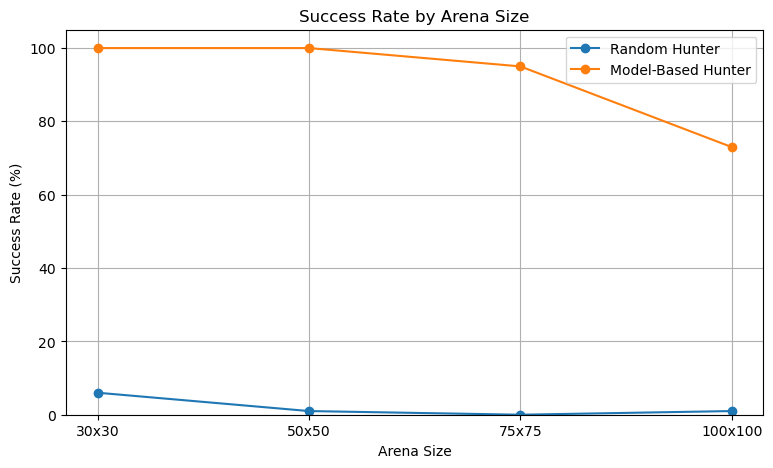

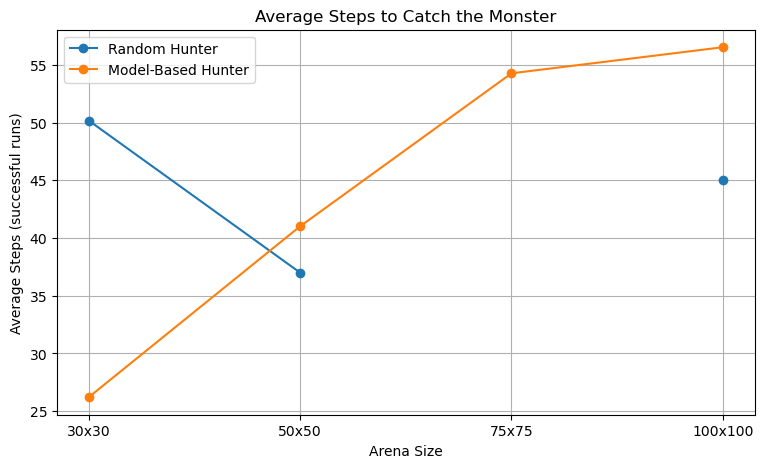

In [52]:
import pandas as pd
import matplotlib.pyplot as plt

#Create a new agent every time you run on a new arena
#Mistakenly avoiding duplication with previous data
def new_model_based():
    return modelbased().act

def new_random_hunter():
    return simple_randomized_hunter_agent_function

def run_experiment(agent_factory, arena_size, runs=100, max_steps=100, seed=12345):
    np.random.seed(seed)
    step_results = []

    for i in range(runs):
        agent_function = agent_factory()
        result = arena_environment(
            agent_function,
            monster_agent_function_simple,
            n=arena_size,
            max_steps=max_steps,
            visualize=False
        )
        step_results.append(result)

    step_results = np.asarray(step_results, dtype=float)
    success_mask = ~np.isnan(step_results)

    return {
        "Arena": f"{arena_size}x{arena_size}",
        "Agent": None,
        "Runs": runs,
        "Successful": int(np.sum(success_mask)),
        "Failed": int(np.sum(~success_mask)),
        "Success Rate (%)": round(float(np.mean(success_mask) * 100), 2),
        "Average Steps": round(float(np.nanmean(step_results)), 2) if np.any(success_mask) else np.nan
    }

results = []

for n in [30, 50, 75, 100]:
    random_result = run_experiment(new_random_hunter, n, runs=100, max_steps=100, seed=20260925 + n)
    random_result["Agent"] = "Random Hunter"
    results.append(random_result)

    model_result = run_experiment(new_model_based, n, runs=100, max_steps=100, seed=20260925 + n)
    model_result["Agent"] = "Model-Based Hunter"
    results.append(model_result)

results_df = pd.DataFrame(results)
results_df = results_df[[
    "Arena", "Agent", "Runs", "Successful", "Failed",
    "Success Rate (%)", "Average Steps"
]]

print("Experimental results:")
display(results_df)

#Plot 1: Success rate comparison
plt.figure(figsize=(9, 5))
for agent in results_df["Agent"].unique():
    data = results_df[results_df["Agent"] == agent]
    plt.plot(data["Arena"], data["Success Rate (%)"], marker="o", label=agent)
plt.xlabel("Arena Size")
plt.ylabel("Success Rate (%)")
plt.title("Success Rate by Arena Size")
plt.ylim(0, 105)
plt.grid(True)
plt.legend()
plt.show()

#Plot 2: Average steps comparison
plt.figure(figsize=(9, 5))
for agent in results_df["Agent"].unique():
    data = results_df[results_df["Agent"] == agent]
    plt.plot(data["Arena"], data["Average Steps"], marker="o", label=agent)
plt.xlabel("Arena Size")
plt.ylabel("Average Steps (successful runs)")
plt.title("Average Steps to Catch the Monster")
plt.grid(True)
plt.legend()
plt.show()

## Your Conclusion [4 points] 

Discuss the following:

* What is your hunter's final strategy to choose actions. Why does it work well?
* Do you use teleportation. Why and in what situation? Why not?
* How does the arena size affects your hunter agent's performance?

* The hunter's ultimate strategy for choosing an action is to `listen` to find out the monster's location, which is then saved in memory so the hunter can move to the monster as accurately as possible. The reason it works well is that the hunter has a clear and precise path, rather than moving around randomly.
* In this strategy, teleportation isn't used. Because teleportation in this game works randomly, it can either help the hunter get closer to the monster or, on the contrary, make it less accurate and less effective.
* The size of the arena has quite an impact on the hunter's performance. Because once the arena is big, the hunter might take a lot of steps or might not be able to catch the monster within the given number of steps.

The monster is also an agent. Describe how the monster's agent function could be changed so it gets better at avoiding the hunter.

The monster is being randomly moved in any of the four directions or stays still, even though it’s been given the hunter’s position each turn. So, to help the monster avoid the hunter better, we use the hunter’s previous positions to help the monster choose moves that get it as far away from the hunter as possible.

# More Work (Optional)

Here are some ideas:

* Implement a better monster agent function and perform experiments
* Change the environment so multiple hunters can hunt the monster.
* Give the hunter a new action that shoots an arrow in a specific direction. 
  The arrow can go a maximum of 5 squares. If the hunter hits the monster, then it wins.